In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully")


Libraries imported successfully


In [9]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))
print("Dataset loaded successfully")

Saving Housing.csv to Housing (1).csv
Dataset loaded successfully


In [10]:
print("First 5 Rows:")
display(df.head())

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

First 5 Rows:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Dataset Shape: (545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea       

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [12]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:", df.duplicated().sum())

df = df.drop_duplicates()

df = df.copy()

for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nData Cleaning Completed")

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Values: 0

Data Cleaning Completed


In [13]:
prices = df['price'].to_numpy()
areas = df['area'].to_numpy()

print("Average Price:", np.mean(prices))
print("Maximum Price:", np.max(prices))
print("Minimum Price:", np.min(prices))
print("Median Price:", np.median(prices))
print("Standard Deviation:", np.std(prices))

print("\nPrice Per Square Unit:")
print(prices / areas)

Average Price: 4766729.247706422
Maximum Price: 13300000
Minimum Price: 1750000
Median Price: 4340000.0
Standard Deviation: 1868722.8281312082

Price Per Square Unit:
[1792.45283019 1367.1875     1229.91967871 1628.66666667 1537.73584906
 1446.66666667 1182.98368298  626.54320988 1218.51851852 1704.34782609
  742.42424242 1613.5        1421.3740458  2640.         1184.61538462
 1516.66666667 1378.78787879 1054.11764706 1932.60869565 1379.2834891
 2025.46296296 1213.13766597 1073.91304348 1895.83333333  974.43181818
 1305.81039755 1410.5         946.47887324 1056.60377358 1527.27272727
 1123.7458194  1200.         1699.79508197 1374.16107383 1187.13450292
 1154.42       1074.97995188  886.66666667 1327.08333333 1318.33333333
 1202.29007634 1232.70440252 1188.27160494 1283.33333333 1260.
 1260.         1254.16666667 1134.84848485 1733.72093023  997.31182796
  997.31182796 1173.12252964 1225.         1427.18446602 1225.
 1225.          641.87062937  805.          938.80208333 1201.6666666

In [14]:
df['price_per_sqft'] = df['price'] / df['area']

print("Houses with Area Greater Than 5000:")
display(df[df['area'] > 5000].head())

print("\nHouses with 3 or More Bedrooms:")
display(df[df['bedrooms'] >= 3].head())

print("\nTop 10 Expensive Houses:")
display(df.sort_values('price', ascending=False).head(10))

Houses with Area Greater Than 5000:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price_per_sqft
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished,1792.452830
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished,1367.187500
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished,1229.919679
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished,1628.666667
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished,1537.735849



Houses with 3 or More Bedrooms:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price_per_sqft
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished,1792.452830
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished,1367.187500
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished,1229.919679
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished,1628.666667
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished,1537.735849



Top 10 Expensive Houses:


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price_per_sqft
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished,1792.452830
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished,1367.187500
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished,1229.919679
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished,1628.666667
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished,1537.735849
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished,1446.666667
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished,1182.983683
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished,626.543210
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished,1218.518519
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished,1704.347826


In [15]:
grouped = df.groupby('furnishingstatus').agg(
    Average_Price=('price', 'mean'),
    Maximum_Price=('price', 'max'),
    Minimum_Price=('price', 'min'),
    Total_Houses=('price', 'count')
)

display(grouped)

,Average_Price,Maximum_Price,Minimum_Price,Total_Houses
furnishingstatus,,,,
furnished,5.495696e+06,13300000,1750000,140
semi-furnished,4.907524e+06,12250000,1767150,227
unfurnished,4.013831e+06,10150000,1750000,178


In [16]:
pivot = pd.pivot_table(
    df,
    values='price',
    index='furnishingstatus',
    columns='airconditioning',
    aggfunc='mean'
)

display(pivot)

airconditioning,no,yes
furnishingstatus,,
furnished,4.469500e+06,6.786717e+06
semi-furnished,4.557951e+06,5.778769e+06
unfurnished,3.583342e+06,5.286167e+06


In [17]:
df['house_id'] = range(1, len(df) + 1)

data1 = df[['house_id', 'price', 'area', 'bedrooms']]

data2 = df[['house_id', 'bathrooms', 'stories', 'parking']]

merged = pd.merge(data1, data2, on='house_id')

display(merged.head())

,house_id,price,area,bedrooms,bathrooms,stories,parking
0,1,13300000,7420,4,2,3,2
1,2,12250000,8960,4,4,4,3
2,3,12250000,9960,3,2,2,2
3,4,12215000,7500,4,2,2,3
4,5,11410000,7420,4,1,2,2


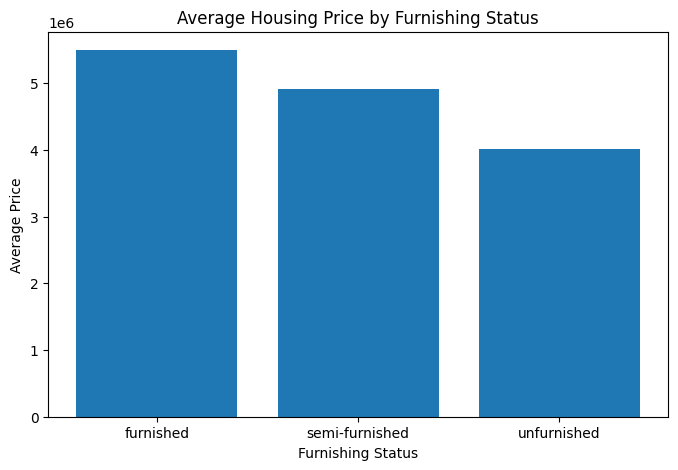

In [18]:
plt.figure(figsize=(8,5))

plt.bar(grouped.index, grouped['Average_Price'])

plt.title("Average Housing Price by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Average Price")

plt.show()

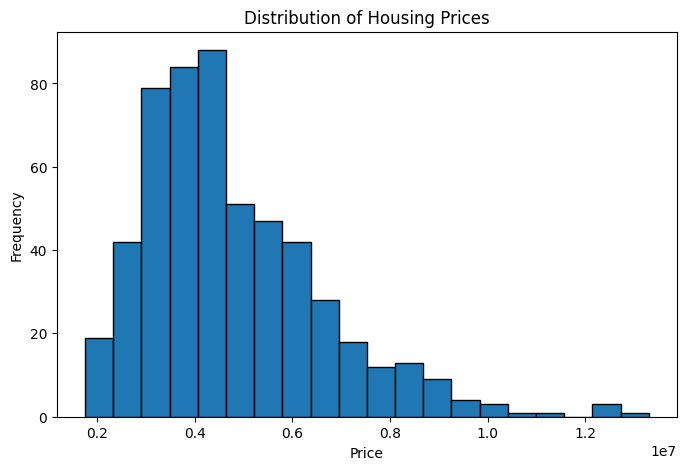

In [19]:
plt.figure(figsize=(8,5))

plt.hist(df['price'], bins=20, edgecolor='black')

plt.title("Distribution of Housing Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

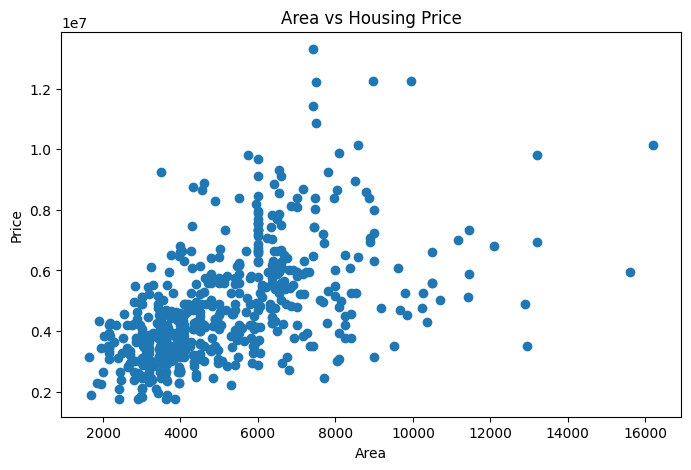

In [20]:
plt.figure(figsize=(8,5))

plt.scatter(df['area'], df['price'])

plt.title("Area vs Housing Price")
plt.xlabel("Area")
plt.ylabel("Price")

plt.show()

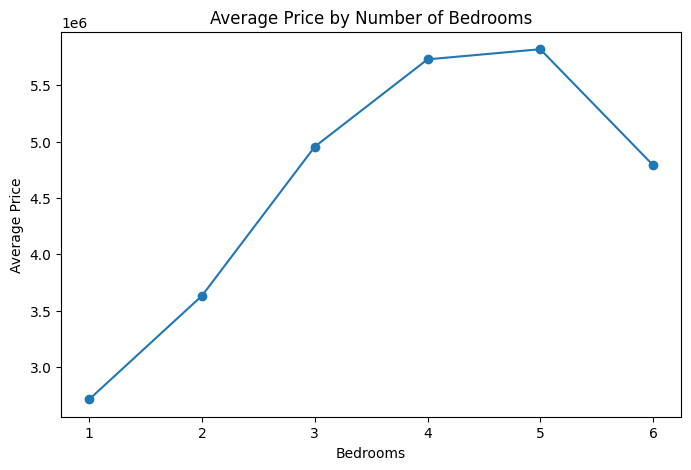

In [21]:
bedroom_data = df.groupby('bedrooms')['price'].mean()

plt.figure(figsize=(8,5))

plt.plot(bedroom_data.index, bedroom_data.values, marker='o')

plt.title("Average Price by Number of Bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Average Price")

plt.show()

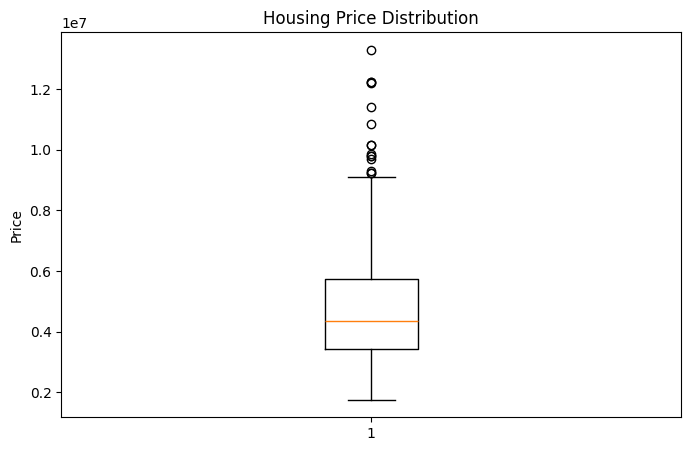

In [22]:
plt.figure(figsize=(8,5))

plt.boxplot(df['price'])

plt.title("Housing Price Distribution")
plt.ylabel("Price")

plt.show()

In [23]:
print("PROJECT SUMMARY")

print("Total Houses:", len(df))

print("Average Price:", df['price'].mean())

print("Average Area:", df['area'].mean())

print("Maximum Price:", df['price'].max())

print("Minimum Price:", df['price'].min())

print("\nProject Completed Successfully!")

PROJECT SUMMARY
Total Houses: 545
Average Price: 4766729.247706422
Average Area: 5150.54128440367
Maximum Price: 13300000
Minimum Price: 1750000

Project Completed Successfully!


In [24]:
df.to_csv("Housing_Analysis_Results.csv", index=False)

from google.colab import files
files.download("Housing_Analysis_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>